# 03 — Tìm các lần dừng (stay detection)

**Input:** toàn bộ GPS đã làm sạch ở notebook 02. **Output:** mỗi hàng là một lần dừng, chưa phải một địa điểm thường ghé hay Home/Office.

Notebook đọc lần lượt từng trajectory của **mọi user**, không lấy mẫu. Chỉ giữ một trajectory và các stay events trong RAM, không nạp toàn bộ 24 triệu points cùng lúc.

Các ngưỡng ban đầu là **100 m / 10 phút / gap tối đa 5 phút**. Đây là rule để thử, chưa phải ngưỡng tối ưu. Notebook không cần train model.

## 1. Mở dữ liệu sau phase 2

Chọn kernel **Python (GeoLife)**. Bước này kiểm tra NB02 đã hoàn thành trên toàn dataset và đọc đúng file `cleaned_points.csv.gz`. Không đọc lại PLT, không cleaning lần nữa.

In [1]:
from pathlib import Path
from collections import Counter
from dataclasses import replace
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'geolife_inference').is_dir())
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Hãy chọn kernel Python (GeoLife).'

from geolife_inference.config import Config
from geolife_inference.stays import STAY_COLUMNS, detect_stays, split_overlapping_stays

PREP = ROOT / 'artifacts' / 'preprocessing'
OUT = ROOT / 'artifacts' / 'stays'
OUT.mkdir(parents=True, exist_ok=True)
CLEANED = PREP / 'cleaned_points.csv.gz'
AUDIT_PATH = PREP / 'audit.json'
prep_audit = json.loads(AUDIT_PATH.read_text(encoding='utf-8'))
assert CLEANED.is_file(), 'Chạy notebook 02 trước để có dữ liệu sạch.'
assert prep_audit['scope'] == 'full_dataset' and prep_audit['status'] == 'completed'
assert prep_audit['conflict_policy'] == 'spatial_vote_context_v2'
assert prep_audit['completed_user_count'] == prep_audit['expected_user_count']
assert prep_audit['processed_trajectory_files'] == prep_audit['expected_trajectory_files']
expected = pd.DataFrame(prep_audit['per_user']).set_index('user_id')
assert expected.index.is_unique and set(expected.index) == set(prep_audit['expected_users'])

# Phát hiện nếu NB02 ghi lại input trong khi NB03 đang chạy.
def input_signature():
    return {str(p.relative_to(ROOT)): {'bytes': p.stat().st_size, 'mtime_ns': p.stat().st_mtime_ns}
            for p in [CLEANED, AUDIT_PATH]}

INPUT_SIGNATURE = input_signature()
print(f"NB02: {prep_audit['completed_user_count']} users / "
      f"{prep_audit['processed_trajectory_files']:,} trajectories / "
      f"{prep_audit['totals']['output_points']:,} cleaned points")
print('Conflict policy:', prep_audit['conflict_policy'], '| Ngưỡng gộp:', prep_audit['merge_threshold_m'], 'm')

NB02: 182 users / 18,670 trajectories / 24,177,772 cleaned points
Conflict policy: spatial_vote_context_v2 | Ngưỡng gộp: 20.0 m


## 2. Rule tìm lần dừng

1. Lấy điểm đầu làm **mốc cố định (anchor)**, rồi xét các điểm tiếp theo theo thời gian.
2. Tiếp tục một candidate khi mỗi điểm còn cách mốc **≤ 100 m**, khoảng cách thời gian tới điểm trước **≤ 5 phút** và vẫn cùng đoạn quan sát.
3. Gặp điểm vượt điều kiện thì kết thúc candidate tại **điểm hợp lệ cuối cùng**. Điểm vừa vượt điều kiện trở thành mốc mới.
4. Giữ candidate nếu thời gian từ điểm đầu đến điểm cuối **≥ 10 phút**. Cuối trajectory cũng kiểm tra candidate còn lại.

Ví dụ: các điểm ở phút 0, 5, 10 quanh mốc → một stay 10 phút. Chỉ có hai điểm ở phút 0 và 10 → gap 10 phút, **không** đủ bằng chứng để tính là dừng.

Không nối giữa hai user, hai trajectory hoặc hai `observation_segment`. Vì vậy, timestamp chưa giải quyết ở NB02 vẫn ngắt chuỗi dù các điểm hai bên rất gần nhau.

**Lưu ý:** 100 m là khoảng cách tới mốc đầu, không phải khoảng cách lớn nhất giữa mọi cặp điểm. Hai điểm trong stay có thể cách nhau gần 200 m. Vị trí đại diện dùng median tọa độ, có xử lý kinh độ qua ±180°. Đi bộ chậm vẫn có thể bị nhận nhầm là dừng.

In [2]:
CONFIG = Config(distance_m=100.0, min_stay_minutes=10.0,
                max_gap_minutes=5.0)
# Segment của NB02 đã được cắt theo gap 5 phút. Không tăng ngưỡng ở đây
# để nối lại các đoạn đã cắt; muốn đổi policy đó cần chạy lại NB02.
assert CONFIG.max_gap_minutes <= prep_audit['max_gap_minutes']
CHUNK_SIZE = 100_000  # Kích thước đọc file, KHÔNG phải giới hạn số points xử lý.
display(pd.Series({
    'Khoảng cách tới mốc (m)': CONFIG.distance_m,
    'Thời gian dừng tối thiểu (phút)': CONFIG.min_stay_minutes,
    'Gap tối đa (phút)': CONFIG.max_gap_minutes,
    'Phạm vi': 'Toàn bộ cleaned dataset',
}, name='Thiết lập'))

Khoảng cách tới mốc (m)                              100.0
Thời gian dừng tối thiểu (phút)                       10.0
Gap tối đa (phút)                                      5.0
Phạm vi                            Toàn bộ cleaned dataset
Name: Thiết lập, dtype: object

## 3. Đọc toàn bộ dữ liệu, giữ nguyên ranh giới trajectory

File nén được đọc thành các khối nhỏ để giảm RAM. Nếu một trajectory nằm vắt qua hai khối, phần cuối được giữ lại và ghép tiếp trước khi tìm stay. **Ranh giới khối đọc không phải ranh giới lần dừng.**

In [3]:
def iter_clean_trajectories():
    columns = ['user_id', 'trajectory_id', 'latitude', 'longitude',
               'timestamp', 'observation_segment']
    types = {'user_id': 'string', 'trajectory_id': 'string',
             'latitude': 'float64', 'longitude': 'float64',
             'observation_segment': 'int64'}
    carry = None
    with pd.read_csv(CLEANED, usecols=columns, dtype=types,
                     chunksize=CHUNK_SIZE) as reader:
        for chunk in reader:
            if chunk.empty:
                continue
            chunk['timestamp'] = pd.to_datetime(chunk['timestamp'], utc=True, errors='raise')
            assert not chunk[columns].isna().any().any(), 'Input có giá trị thiếu không hợp lệ.'
            if carry is not None:
                chunk = pd.concat([carry, chunk], ignore_index=True)
            # Mỗi block liên tiếp là một (user, trajectory).
            starts = np.flatnonzero(
                chunk['user_id'].ne(chunk['user_id'].shift()).fillna(True).to_numpy(dtype=bool)
                | chunk['trajectory_id'].ne(chunk['trajectory_id'].shift()).fillna(True).to_numpy(dtype=bool)
            )
            for start, end in zip(starts[:-1], starts[1:]):
                yield chunk.iloc[start:end].copy()
            carry = chunk.iloc[starts[-1]:].copy()
    if carry is not None and not carry.empty:
        yield carry

## 4. Chạy detector và kiểm tra đủ phạm vi

Mỗi trajectory đi qua cùng một detector. Cuối lượt chạy, số points và số trajectories **của từng user** phải khớp audit NB02; thiếu dữ liệu thì báo lỗi, không ghi trạng thái hoàn thành.

Bảng candidate giữ các lần dừng đạt rule trước khi xử lý việc hai file trajectory có thời gian chồng nhau.

In [4]:
def scan_all_stays(config):
    assert config.max_gap_minutes <= prep_audit['max_gap_minutes']
    assert input_signature() == INPUT_SIGNATURE, 'Input đã đổi; chạy lại từ phần 1.'
    events, seen = [], set()
    point_counts, trajectory_counts = Counter(), Counter()
    for frame in iter_clean_trajectories():
        user = str(frame['user_id'].iloc[0])
        trajectory = str(frame['trajectory_id'].iloc[0])
        key = (user, trajectory)
        assert key not in seen, f'Trajectory không nằm liên tiếp trong CSV: {key}'
        assert user in expected.index, f'User ngoài audit: {user}'
        assert frame['timestamp'].is_monotonic_increasing, f'Thời gian không tăng: {key}'
        assert not frame['timestamp'].duplicated().any(), f'Còn trùng timestamp: {key}'
        assert frame['observation_segment'].is_monotonic_increasing, f'Segment bị đảo: {key}'
        seen.add(key)
        point_counts[user] += len(frame)
        trajectory_counts[user] += 1
        stays, audit = detect_stays(frame, config)
        assert audit['overlapping_stays_removed'] == 0  # Một trajectory, thời gian tăng nghiêm ngặt.
        if not stays.empty:
            events.append(stays)
        if len(seen) % 1000 == 0:
            print(f'Đã xử lý {len(seen):,} trajectories / {sum(point_counts.values()):,} points')

    coverage = pd.DataFrame({
        'user_id': expected.index,
        'processed_points': [point_counts[u] for u in expected.index],
        'processed_trajectories': [trajectory_counts[u] for u in expected.index],
    }).set_index('user_id')
    assert coverage['processed_points'].eq(expected['output_points']).all(), 'Số points từng user không khớp NB02.'
    assert coverage['processed_trajectories'].eq(expected['after_trajectories']).all(), 'Số trajectories từng user không khớp NB02.'
    assert int(coverage['processed_points'].sum()) == prep_audit['totals']['output_points']
    assert input_signature() == INPUT_SIGNATURE, 'Input đổi trong lúc chạy; không dùng kết quả này.'
    candidates = pd.concat(events, ignore_index=True) if events else pd.DataFrame(columns=STAY_COLUMNS)
    print(f"Hoàn tất: {len(coverage)} users / {len(seen):,} trajectories / {sum(point_counts.values()):,} points")
    return candidates, coverage

In [5]:
run_audit = {
    'status': 'running', 'scope': 'full_dataset', 'detector': 'anchor-v2-segment-aware',
    'config': {k: CONFIG.to_dict()[k] for k in ['distance_m', 'min_stay_minutes', 'max_gap_minutes']},
    'input': INPUT_SIGNATURE,
    'preprocessing_fingerprint': prep_audit['dataset_fingerprint'],
    'preprocessing_policy': prep_audit['conflict_policy'],
    'preprocessing_merge_threshold_m': prep_audit['merge_threshold_m'],
}
def write_run_audit():
    target = OUT / 'audit.json'
    partial = target.with_suffix('.json.partial')
    partial.write_text(json.dumps(run_audit, indent=2, ensure_ascii=False), encoding='utf-8')
    partial.replace(target)

write_run_audit()
try:
    candidates, coverage = scan_all_stays(CONFIG)
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_run_audit()
    raise
print(f'Có {len(candidates):,} candidate stays đạt rule, trước xử lý overlap.')

Đã xử lý 1,000 trajectories / 1,316,177 points
Đã xử lý 2,000 trajectories / 3,368,166 points
Đã xử lý 3,000 trajectories / 5,145,407 points
Đã xử lý 4,000 trajectories / 6,582,529 points
Đã xử lý 5,000 trajectories / 8,583,530 points
Đã xử lý 6,000 trajectories / 10,320,965 points
Đã xử lý 7,000 trajectories / 11,751,422 points
Đã xử lý 8,000 trajectories / 13,223,867 points
Đã xử lý 9,000 trajectories / 14,786,403 points
Đã xử lý 10,000 trajectories / 15,683,368 points
Đã xử lý 11,000 trajectories / 16,543,039 points
Đã xử lý 12,000 trajectories / 17,407,364 points
Đã xử lý 13,000 trajectories / 17,944,618 points
Đã xử lý 14,000 trajectories / 18,760,812 points
Đã xử lý 15,000 trajectories / 19,727,976 points
Đã xử lý 16,000 trajectories / 20,750,743 points
Đã xử lý 17,000 trajectories / 21,865,233 points
Đã xử lý 18,000 trajectories / 23,019,645 points
Hoàn tất: 182 users / 18,670 trajectories / 24,177,772 points
Có 10,339 candidate stays đạt rule, trước xử lý overlap.


## 5. Xử lý các lần dừng chồng thời gian và lưu kết quả

Hai file trajectory của cùng một user có thể chồng thời gian. Để không đếm hai lần cùng một khoảng thời gian, sắp tất cả candidate của user theo giờ bắt đầu; **giữ lần bắt đầu trước**, tách riêng lần phía sau nếu bị chồng. Hai lần chỉ chạm nhau ở một thời điểm vẫn được giữ.

Đây là quy tắc tránh đếm trùng, **không chứng minh file được giữ đúng hơn**. Không cắt ngắn lần bị chồng vì chưa kiểm tra lại các GPS points tạo nên phần bị cắt. Các lần tách riêng vẫn có trong `overlapping_stays.csv` để xem lại; không xóa GPS input.

In [6]:
try:
    stays, overlaps = split_overlapping_stays(candidates)
    stays.insert(0, 'stay_id', [f'{u}_s{n:06d}' for u, n in zip(
        stays['user_id'], stays.groupby('user_id', sort=False).cumcount() + 1)])
    assert len(stays) + len(overlaps) == len(candidates)
    assert stays['duration_minutes'].ge(CONFIG.min_stay_minutes).all()
    assert stays['point_count'].ge(2).all()
    for column in ['start_time', 'end_time']:
        stays[column] = pd.to_datetime(stays[column], utc=True)
    assert stays['end_time'].sub(stays['start_time']).dt.total_seconds().div(60).eq(stays['duration_minutes']).all()

    per_user = coverage.join(stays.groupby('user_id').agg(
        stay_count=('stay_id', 'size'), stay_minutes=('duration_minutes', 'sum'),
        points_in_stays=('point_count', 'sum')))
    for column in ['stay_count', 'stay_minutes', 'points_in_stays']:
        per_user[column] = pd.to_numeric(per_user[column], errors='raise').fillna(0)
    per_user['stay_count'] = per_user['stay_count'].astype('int64')
    per_user['points_in_stays'] = per_user['points_in_stays'].astype('int64')
    per_user['overlapping_stays'] = overlaps.groupby('user_id').size().reindex(per_user.index, fill_value=0)
    assert per_user['points_in_stays'].le(per_user['processed_points']).all()

    # Mỗi file chỉ thay thế bản chính sau khi ghi xong; audit completed ghi sau cùng.
    for name, table, index in [('stays.csv', stays, False),
                               ('overlapping_stays.csv', overlaps, False),
                               ('per_user.csv', per_user, True)]:
        partial = OUT / (name + '.partial')
        table.to_csv(partial, index=index)
        partial.replace(OUT / name)
    assert input_signature() == INPUT_SIGNATURE, 'Input đã đổi; cần chạy lại từ phần 1.'
    run_audit.update(
        status='completed', processed_users=len(coverage),
        processed_trajectories=int(coverage['processed_trajectories'].sum()),
        processed_points=int(coverage['processed_points'].sum()),
        candidate_stays=len(candidates), overlapping_stays_removed=len(overlaps),
        stay_events=len(stays), users_with_stays=int(per_user['stay_count'].gt(0).sum()),
        stay_minutes=float(stays['duration_minutes'].sum()),
        points_in_stays=int(stays['point_count'].sum()),
        per_user=per_user.reset_index().to_dict('records'))
    write_run_audit()
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_run_audit()
    raise

display(pd.Series({
    'Users đã xử lý': len(per_user),
    'Users có stay': run_audit['users_with_stays'],
    'Stays được giữ': len(stays),
    'Stays tách riêng vì overlap': len(overlaps),
    'Tổng thời gian trong stays (giờ)': stays['duration_minutes'].sum() / 60,
    'Points thuộc stays / mọi cleaned points': stays['point_count'].sum() / max(1, run_audit['processed_points']),
}, name='Kết quả toàn dataset'))
display(stays.head(10))

Users đã xử lý                               182.000000
Users có stay                                151.000000
Stays được giữ                             10339.000000
Stays tách riêng vì overlap                    0.000000
Tổng thời gian trong stays (giờ)            3592.999444
Points thuộc stays / mọi cleaned points        0.107334
Name: Kết quả toàn dataset, dtype: float64

,stay_id,user_id,trajectory_id,latitude,longitude,start_time,end_time,duration_minutes,point_count,observation_segment
0,000_s000001,000,20081023025304,40.009025,116.321502,2008-10-23 09:45:05+00:00,2008-10-23 09:55:51+00:00,10.766667,97,3
1,000_s000002,000,20081028003826,40.011581,116.296897,2008-10-28 00:50:51+00:00,2008-10-28 01:11:06+00:00,20.250000,233,2
2,000_s000003,000,20081103232153,40.011371,116.296895,2008-11-04 00:52:33+00:00,2008-11-04 01:10:08+00:00,17.583333,235,3
3,000_s000004,000,20081103232153,40.006912,116.295890,2008-11-04 01:37:53+00:00,2008-11-04 01:54:08+00:00,16.250000,135,4
4,000_s000005,000,20081103232153,40.006558,116.297088,2008-11-04 02:07:58+00:00,2008-11-04 02:22:48+00:00,14.833333,107,4
5,000_s000006,000,20081111001704,40.011513,116.296847,2008-11-11 00:34:29+00:00,2008-11-11 00:51:09+00:00,16.666667,220,2
6,000_s000007,000,20081112023003,40.008916,116.321504,2008-11-12 04:52:19+00:00,2008-11-12 05:03:49+00:00,11.500000,82,6
7,000_s000008,000,20090330005208,40.009731,116.315104,2009-03-30 05:25:25+00:00,2009-03-30 05:38:35+00:00,13.166667,137,3
8,000_s000009,000,20090331003904,39.990652,116.317315,2009-03-31 10:23:35+00:00,2009-03-31 10:54:08+00:00,30.550000,406,10
9,000_s000010,000,20090402060732,40.010616,116.322360,2009-04-02 09:54:26+00:00,2009-04-02 10:10:51+00:00,16.416667,122,2


### Các cột trong `stays.csv`

| Cột | Ý nghĩa |
|---|---|
| `stay_id` | ID lần dừng, dùng trong các bước sau; thay đổi rule có thể đổi ID |
| `user_id`, `trajectory_id`, `observation_segment` | User, file trajectory và đoạn quan sát tạo ra lần dừng |
| `latitude`, `longitude` | Vị trí đại diện bằng median, đơn vị độ |
| `start_time`, `end_time` | Thời điểm GPS đầu/cuối của stay, lưu UTC |
| `duration_minutes` | Số phút giữa hai thời điểm trên, không cộng thời gian qua gap bị ngắt |
| `point_count` | Số **cleaned points** tạo nên stay, không phải số raw points trước gộp ở NB02 |

Một user ghé lại cùng chỗ vào hai thời điểm khác nhau sẽ có hai stay events. Phase 4 mới gom các lần ghé thành địa điểm.

Tỷ lệ points thuộc stays phụ thuộc tần suất ghi GPS, **không phải tỷ lệ thời gian đứng yên**. Tổng giờ trong stays là bằng chứng từ chuỗi GPS thỏa rule, không phải toàn bộ thời gian dừng thực tế.

## 6. Phân phối thời gian dừng trên toàn dataset

**X:** thời lượng một stay, tính bằng phút, thang log. **Y:** số stay events trong từng khoảng thời lượng. Mỗi stay đóng góp đúng một lần; chỉ dùng các stays đã giữ sau overlap.

Bảng percentile giúp đọc phần đuôi: P90 nghĩa là 90% stays có thời lượng không vượt giá trị đó. Stay rất dài cần được xem lại; biểu đồ không chứng minh detector chính xác.

count    10339.000000
mean        20.851143
std         19.976419
min         10.000000
50%         15.416667
90%         34.266667
95%         47.536667
99%         99.250333
max        620.500000
Name: Thời lượng stay (phút), dtype: float64

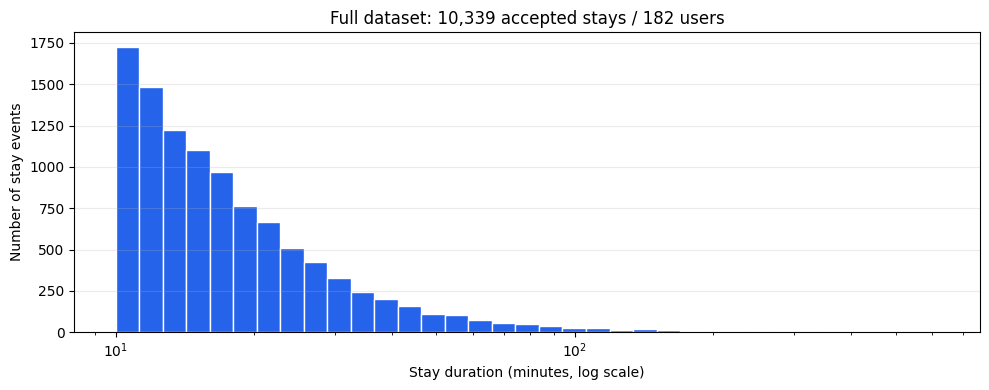

10 stays dài nhất để xem phần đuôi (thời gian hiển thị theo Asia/Shanghai):


,stay_id,user_id,trajectory_id,latitude,longitude,start_time,end_time,duration_minutes,point_count,observation_segment
9075,144_s000180,144,20090720000052,40.027300,116.432972,2009-07-20 18:43:27+08:00,2009-07-21 05:03:57+08:00,620.500000,7475,2
9089,144_s000194,144,20090804110750,40.027503,116.432589,2009-08-05 01:57:10+08:00,2009-08-05 07:56:40+08:00,359.500000,4320,2
9066,144_s000171,144,20090717111355,40.027461,116.432968,2009-07-18 03:19:20+08:00,2009-07-18 08:50:15+08:00,330.916667,3977,2
5544,051_s000030,051,20080204133623,30.922182,117.821200,2008-02-04 21:45:29+08:00,2008-02-05 03:13:35+08:00,328.100000,99,2
5549,051_s000035,051,20080204133623,30.922023,117.821168,2008-02-05 11:53:40+08:00,2008-02-05 17:20:07+08:00,326.450000,112,6
163,001_s000044,001,20081213092204,40.013801,116.306498,2008-12-14 03:40:41+08:00,2008-12-14 09:05:31+08:00,324.833333,3908,6
132,001_s000013,001,20081105110052,40.013789,116.306532,2008-11-06 02:26:22+08:00,2008-11-06 07:43:23+08:00,317.016667,4106,5
7927,113_s000003,113,20100510103524,40.052671,116.400656,2010-05-11 03:21:19+08:00,2010-05-11 08:27:34+08:00,306.250000,3713,4
5545,051_s000031,051,20080204133623,30.922022,117.821113,2008-02-05 03:18:39+08:00,2008-02-05 08:18:29+08:00,299.833333,112,3
3436,028_s000008,028,20090207060326,39.967808,116.101563,2009-02-07 22:24:01+08:00,2009-02-08 02:55:16+08:00,271.250000,3262,3


In [7]:
if stays.empty:
    print('Không có stay đạt rule; vẫn có audit và CSV đủ phạm vi. Có thể thử phần sensitivity bên dưới.')
else:
    durations = stays['duration_minutes']
    display(durations.describe(percentiles=[.5, .9, .95, .99]).rename('Thời lượng stay (phút)'))
    upper = max(float(durations.max()) * 1.001, CONFIG.min_stay_minutes * 1.01)
    bins = np.geomspace(CONFIG.min_stay_minutes, upper, 36)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(durations, bins=bins, color='#2563eb', edgecolor='white')
    ax.set(xscale='log', xlabel='Stay duration (minutes, log scale)', ylabel='Number of stay events',
           title=f'Full dataset: {len(stays):,} accepted stays / {len(per_user)} users')
    ax.grid(axis='y', alpha=.25)
    fig.tight_layout()
    fig.savefig(OUT / '01_stay_duration.png', dpi=150)
    plt.show()
    print('10 stays dài nhất để xem phần đuôi (thời gian hiển thị theo Asia/Shanghai):')
    longest = stays.nlargest(10, 'duration_minutes').copy()
    for col in ['start_time', 'end_time']:
        longest[col] = longest[col].dt.tz_convert(CONFIG.timezone)
    display(longest)

## 7. Mỗi user có bao nhiêu lần dừng?

Cả hai biểu đồ đều có **mọi user**, kể cả user không có stay. **X:** ID user. **Y trái:** số stay events; **Y phải:** tổng số giờ trong các stays của user đó. Nhãn X được hiện cách quãng cho dễ đọc; không bỏ user nào.

User có nhiều stays có thể chỉ vì ghi GPS nhiều hơn. Số stays cao cũng có thể do jitter/gaps làm một lần ghé bị tách thành nhiều đoạn. Chưa dùng các cột này để xếp độ chính xác hoặc gán Home/Office.

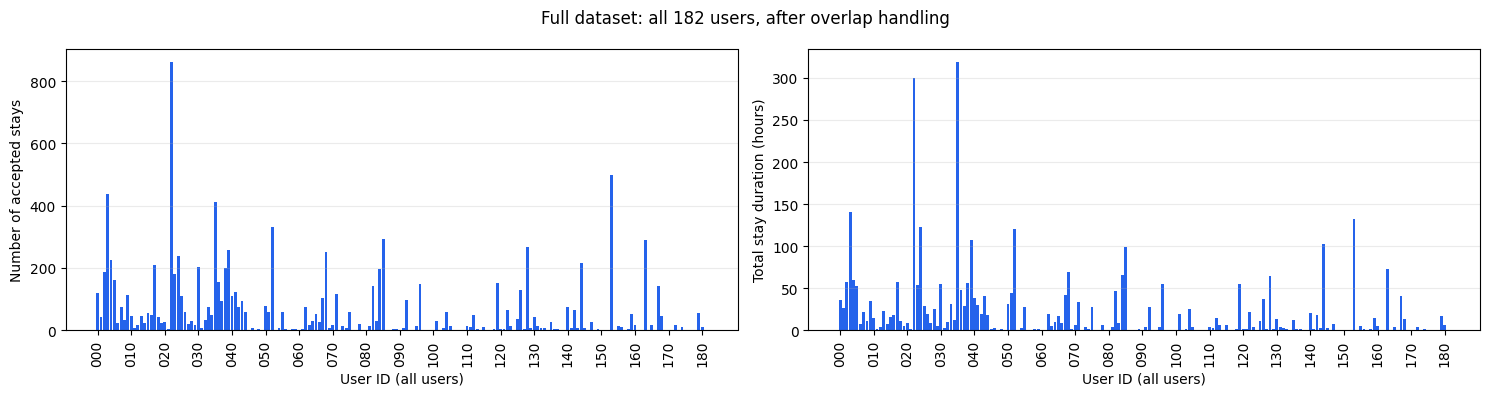

,processed_points,processed_trajectories,stay_count,stay_minutes,points_in_stays,overlapping_stays
user_id,,,,,,
000,173870,171,120,2186.516667,24242,0
001,108607,71,44,1586.933333,18798,0
002,248214,175,188,3410.983333,37388,0
003,485226,322,436,8411.150000,92922,0
004,439397,395,224,3584.316667,37780,0
...,...,...,...,...,...,...
177,2955,1,0,0.000000,0,0
178,84,1,0,0.000000,0,0
179,155312,71,56,984.000000,20709,0


In [8]:
x = np.arange(len(per_user))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, values, ylabel in [
    (axes[0], per_user['stay_count'], 'Number of accepted stays'),
    (axes[1], per_user['stay_minutes'] / 60, 'Total stay duration (hours)'),
]:
    ax.bar(x, values.to_numpy(), width=.85, color='#2563eb')
    ticks = np.arange(0, len(per_user), 10)
    ax.set_xticks(ticks, per_user.index[ticks], rotation=90)
    ax.set(xlabel='User ID (all users)', ylabel=ylabel)
    ax.grid(axis='y', alpha=.25)
fig.suptitle(f'Full dataset: all {len(per_user)} users, after overlap handling')
fig.tight_layout()
fig.savefig(OUT / '02_stays_per_user.png', dpi=150)
plt.show()
display(per_user)

## 8. Thử độ nhạy của ngưỡng — tùy chọn, vẫn chạy toàn dataset

Đổi **một yếu tố mỗi lần** so với baseline: bán kính 50/200 m hoặc thời gian tối thiểu 5/20 phút; giữ gap 5 phút. Mỗi cấu hình xử lý lại **toàn bộ input**, cùng rule overlap, không dùng subset.

Đặt `RUN_SENSITIVITY = True` rồi chạy cell để thử. Bốn lượt full-data có thể mất nhiều thời gian; mặc định tắt để xem kết quả baseline trước. Chỉ xuất bảng so sánh, không ghi đè `stays.csv` baseline.

Số stays tăng/giảm chỉ cho thấy rule nhạy thế nào. Bán kính lớn có thể ghép các điểm thành stay dài hơn và làm **giảm** số events; không kết luận nhiều stays hơn là tốt hơn. Không có nhãn độc lập nên không báo accuracy.

In [10]:
RUN_SENSITIVITY = True  # Nếu muốn chạy sensitivity, đổi thành True; nếu không, giữ False.
if RUN_SENSITIVITY:
    assert run_audit['status'] == 'completed'
    baseline_config = {k: CONFIG.to_dict()[k] for k in run_audit['config']}
    assert baseline_config == run_audit['config'], 'CONFIG đã đổi; chạy lại baseline trước.'
    scenarios = {
        'radius_50m': replace(CONFIG, distance_m=50),
        'radius_200m': replace(CONFIG, distance_m=200),
        'duration_5min': replace(CONFIG, min_stay_minutes=5),
        'duration_20min': replace(CONFIG, min_stay_minutes=20),
    }
    rows = [dict(scenario='baseline', **baseline_config, stays=len(stays),
                 stay_hours=float(stays['duration_minutes'].sum() / 60),
                 overlapping_stays=len(overlaps), processed_points=run_audit['processed_points'])]
    for name, config in scenarios.items():
        print('Cấu hình:', name)
        alternatives, checked_coverage = scan_all_stays(config)
        accepted, excluded = split_overlapping_stays(alternatives)
        rows.append(dict(scenario=name,
                         **{k: config.to_dict()[k] for k in baseline_config},
                         stays=len(accepted), stay_hours=float(accepted['duration_minutes'].sum() / 60),
                         overlapping_stays=len(excluded),
                         processed_points=int(checked_coverage['processed_points'].sum())))
    sensitivity = pd.DataFrame(rows)
    partial = OUT / 'sensitivity.csv.partial'
    sensitivity.to_csv(partial, index=False)
    partial.replace(OUT / 'sensitivity.csv')
    display(sensitivity)
else:
    print('Chưa chạy sensitivity. Baseline ở phần 4–7 đã dùng toàn dataset.')

Cấu hình: radius_50m
Đã xử lý 1,000 trajectories / 1,316,177 points
Đã xử lý 2,000 trajectories / 3,368,166 points
Đã xử lý 3,000 trajectories / 5,145,407 points
Đã xử lý 4,000 trajectories / 6,582,529 points
Đã xử lý 5,000 trajectories / 8,583,530 points
Đã xử lý 6,000 trajectories / 10,320,965 points
Đã xử lý 7,000 trajectories / 11,751,422 points
Đã xử lý 8,000 trajectories / 13,223,867 points
Đã xử lý 9,000 trajectories / 14,786,403 points
Đã xử lý 10,000 trajectories / 15,683,368 points
Đã xử lý 11,000 trajectories / 16,543,039 points
Đã xử lý 12,000 trajectories / 17,407,364 points
Đã xử lý 13,000 trajectories / 17,944,618 points
Đã xử lý 14,000 trajectories / 18,760,812 points
Đã xử lý 15,000 trajectories / 19,727,976 points
Đã xử lý 16,000 trajectories / 20,750,743 points
Đã xử lý 17,000 trajectories / 21,865,233 points
Đã xử lý 18,000 trajectories / 23,019,645 points
Hoàn tất: 182 users / 18,670 trajectories / 24,177,772 points
Cấu hình: radius_200m
Đã xử lý 1,000 trajectories

,scenario,distance_m,min_stay_minutes,max_gap_minutes,stays,stay_hours,overlapping_stays,processed_points
0,baseline,100.0,10.0,5.0,10339,3592.999444,0,24177772
1,radius_50m,50.0,10.0,5.0,6024,2068.507500,0,24177772
2,radius_200m,200.0,10.0,5.0,14371,5188.689167,0,24177772
3,duration_5min,100.0,5.0,5.0,27605,5569.005000,0,24177772
4,duration_20min,100.0,20.0,5.0,3174,1959.505278,0,24177772


## Kết quả của phase 3

Sau khi chạy thành công, `artifacts/stays/` có:

- `stays.csv`: các lần dừng được giữ, input cho phase 4.
- `overlapping_stays.csv`: các candidate bị tách riêng vì chồng thời gian.
- `per_user.csv`, `audit.json`: số lượng từng user, cấu hình, input và trạng thái đủ phạm vi.
- `01_stay_duration.png`, `02_stays_per_user.png`: hai chart tổng hợp toàn dataset.
- `sensitivity.csv`: chỉ có khi đã bật và chạy xong phần 8.

Chỉ dùng kết quả khi audit ghi `completed` và counts khớp NB02. Sau khi thay ngưỡng cần chạy lại từ phần 4. Các kết quả cũ còn trên ổ đĩa không đại diện cho một lượt mới đang lỗi hoặc chưa hoàn tất.

Các giới hạn còn lại: GPS trong nhà có thể thiếu; chuyển động chậm có thể thành stay; greedy reset có thể bỏ lỡ stop; rule giữ lần bắt đầu trước chưa xác định được trajectory nào đúng hơn. Chưa có clustering hay gán Home/Office trong notebook này.